In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [2]:
pd.options.display.max_columns = 999

In [3]:
url = r"C:\Users\rergu\OneDrive\IronHack\datasets\amz_uk_price_prediction_dataset.csv"
df = pd.read_csv(url)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [6]:
# frequency table

proportion_table = df['category'].value_counts(normalize=True)
frequency_table = df['category'].value_counts(normalize=True)
frequency_table.sort_values(ascending=False).head(20)

category
Sports & Outdoors                         0.342219
Beauty                                    0.007903
Handmade Clothing, Shoes & Accessories    0.007869
Bath & Body                               0.007813
Birthday Gifts                            0.007766
Manicure & Pedicure Products              0.007751
Skin Care                                 0.007681
Make-up                                   0.007675
Hair Care                                 0.007667
Fragrances                                0.007597
Handmade Gifts                            0.007487
Handmade Home Décor                       0.007426
Luggage and travel gear                   0.007424
Handmade Jewellery                        0.007384
Handmade Artwork                          0.007316
Women                                     0.007273
Handmade Home & Kitchen Products          0.007135
Handmade Kitchen & Dining                 0.007134
Men                                       0.007127
Baby                  

In [8]:
# create crosstable same as value counts but create datraframne

my_cross_table = pd.crosstab(index= df['category'], columns='count').reset_index()
my_cross_table.sort_values(by='count', ascending=False, inplace=True)
my_cross_table.head(10)

col_0,category,count
262,Sports & Outdoors,836265
20,Beauty,19312
116,"Handmade Clothing, Shoes & Accessories",19229
16,Bath & Body,19092
29,Birthday Gifts,18978
177,Manicure & Pedicure Products,18940
251,Skin Care,18769
176,Make-up,18756
111,Hair Care,18735
94,Fragrances,18564


<Axes: xlabel='category', ylabel='count'>

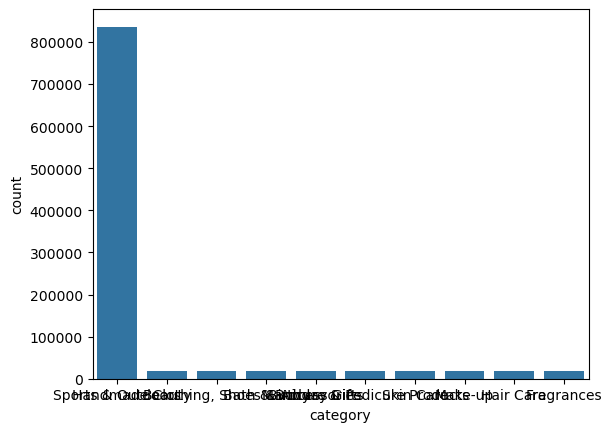

In [9]:
sns.barplot(x=my_cross_table['category'].iloc[:10], y=my_cross_table['count'].iloc[:10])

In [10]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [13]:
price_mean = df['price'].mean()
price_median = df['price'].median()
price_std = df['price'].std()
price_var = df['price'].var()
price_mode = df['price'].mode()[0]
price_min = df['price'].min()
price_max = df['price'].max()
price_range = price_max - price_min
price_mean, price_median, price_std, price_var, price_mode, price_min, price_max, price_range

(89.24380943923663,
 19.09,
 345.60886175352226,
 119445.48532256528,
 9.99,
 0.0,
 100000.0,
 100000.0)

In [14]:
price_quantile = df['price'].quantile([0.25,0.5,0.75])
price_quantile

0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64

In [15]:
price_skweness = df['price'].skew()
price_kurtosis = df['price'].kurtosis()
price_skweness, price_kurtosis

(27.492977566280338, 4241.616412866518)

Text(0.5, 0, 'Price')

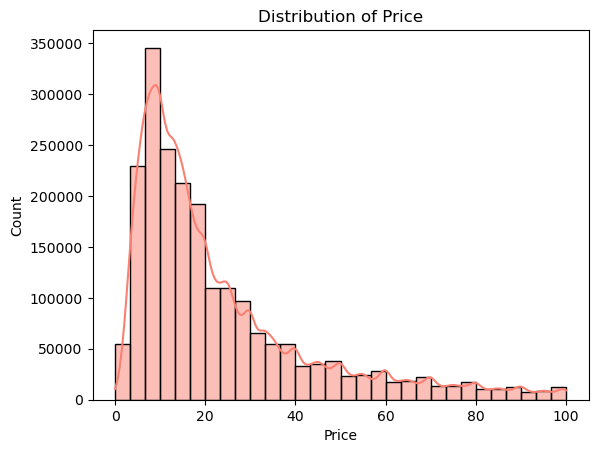

In [16]:
#price smaller than 100
sns.histplot(df[df['price'] < 100]['price'], bins=30,kde=True, color='salmon') 
plt.title('Distribution of Price')
plt.xlabel('Price') 

<Axes: ylabel='price'>

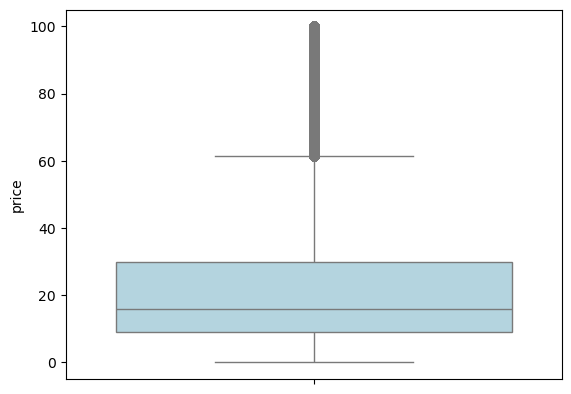

In [18]:
sns.boxplot(data = df[df['price']<100]['price'], color="lightblue")

In [26]:
stars_mean = df[df['stars'] != 0]['stars'].mean()
stars_median = df[df['stars'] != 0]['stars'].median()
stars_std = df[df['stars'] != 0]['stars'].std()
stars_var = df[df['stars'] != 0]['stars'].var()
stars_mode = df[df['stars'] != 0]['stars'].mode()[0]
stars_min = df[df['stars'] != 0]['stars'].min()
stars_max = df[df['stars'] != 0]['stars'].max()
stars_range = stars_max - stars_min
stars_mean, stars_median, stars_std, stars_var, stars_mode, stars_min, stars_max, stars_range

(4.31916076222691,
 4.4,
 0.5552867504614637,
 0.3083433752380519,
 4.5,
 1.0,
 5.0,
 4.0)

In [31]:
stars_quantile = df[df['stars'] != 0]['stars'].quantile([0.25, 0.5, 0.75])
stars_skewness = df[df['stars'] != 0]['stars'].skew()
stars_kurtosis = df[df['stars'] != 0]['stars'].kurtosis()
stars_kurtosis, stars_skewness, stars_quantile

(9.78193769066435,
 -2.3795681122127945,
 0.25    4.1
 0.50    4.4
 0.75    4.6
 Name: stars, dtype: float64)

<Axes: xlabel='stars', ylabel='Count'>

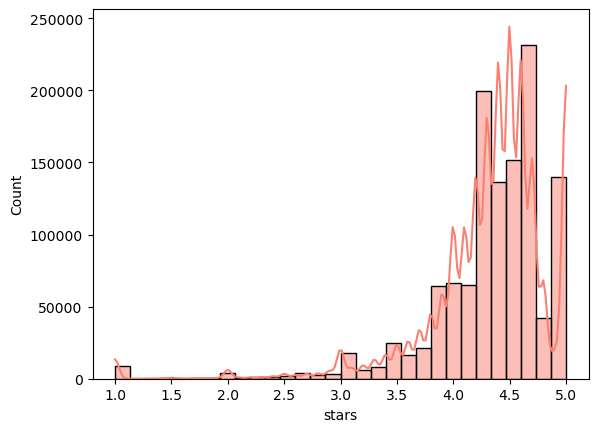

In [23]:
sns.histplot(df[df['stars'] != 0]['stars'], kde=True, bins=30, color='salmon')

<Axes: ylabel='stars'>

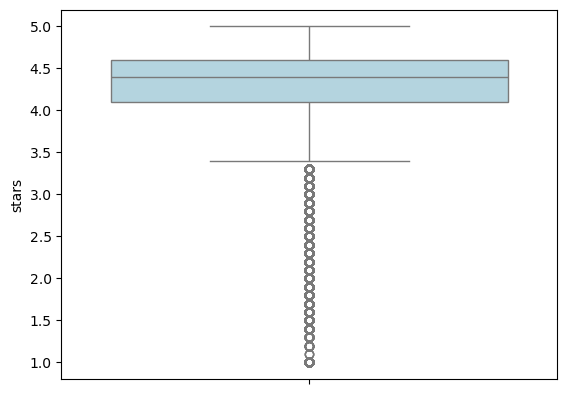

In [24]:
sns.boxplot(data=df[df['stars'] != 0]['stars'], color='lightblue')

In [15]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
117100,126111,B0BCYZP97F,Hamster gift | hamster lover gift funny hamste...,5.0,2,7.95,False,0,Handmade Gifts
385123,411346,B09NQBMDSK,adidas Men's M Fv Pt,5.0,1,31.95,False,0,Sports & Outdoors
385196,411420,B08CZBF29Q,Trespass Men's Trevor - Male Ski Trs Tp75 Trou...,5.0,1,57.99,False,0,Sports & Outdoors
1121792,1240691,B07D5HLWYQ,STANLEY 028590 Window Glass Scraper Paint Stic...,5.0,9,32.85,False,0,"Painting Supplies, Tools & Wall Treatments"
2007292,2258411,B07PZZ57WP,128GB Memory Card (Class 10) for Nokia 2.1,5.0,9,7.72,False,0,Data Storage


In [10]:
my_cross_table = pd.crosstab(index=df['category'], columns=df['isBestSeller'])
#sort values by isBestSeller
my_cross_table_ratio = my_cross_table.sort_values(by=True, ascending=False)
my_cross_table_ratio['ratio'] = my_cross_table[True] / my_cross_table[False]
my_cross_table_ratio = my_cross_table_ratio.sort_values(by='ratio', ascending=False)
my_cross_table_ratio.reset_index().head(20)

isBestSeller,category,False,True,ratio
0,Grocery,9008,556,0.061723
1,Smart Home Security & Lighting,98,6,0.061224
2,Health & Personal Care,9017,552,0.061218
3,Mobile Phone Accessories,248,11,0.044355
4,Power & Hand Tools,8353,306,0.036634
5,"Billiard, Snooker & Pool",241,8,0.033195
6,Pet Supplies,9152,285,0.031141
7,Home Brewing & Wine Making,239,7,0.029289
8,Wind Instruments,243,7,0.028807
9,Mirrors,243,7,0.028807


In [50]:
from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'

chi2_statistic, chi2_p_value, _, _ = chi2_contingency(my_cross_table)

chi2_statistic, chi2_p_value

(36540.20270061387, 0.0)

In [51]:
from scipy.stats.contingency import association

# Computing the association between variables in 'my_cross_table' using the "cramer" method
association(my_cross_table, method="cramer")

0.1222829439760564

<Axes: xlabel='category'>

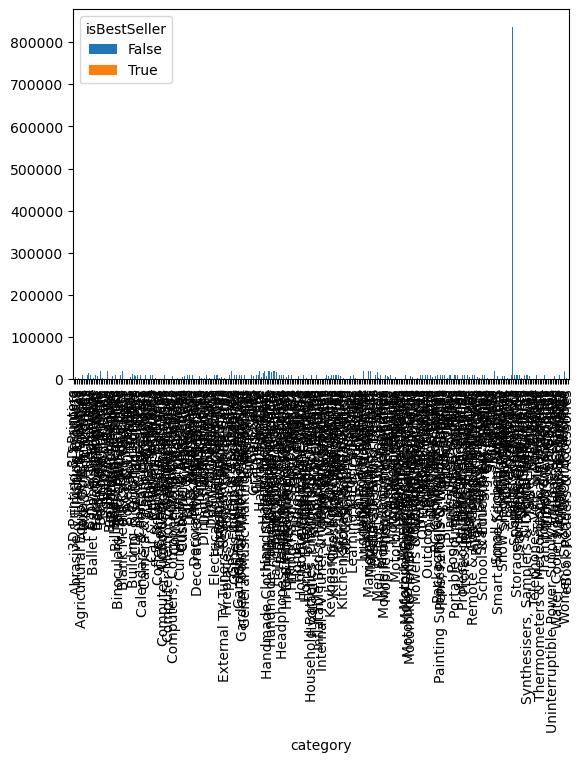

In [11]:

# Plotting a stacked bar chart for the 'my_cross_table' data
my_cross_table.plot(kind="bar", stacked=True)